# DISEASE: HEART DISEASE

### 1.1. Reading the Dataset

### 1.2. General Information

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("C:/Users/User/Documents/diploma/data/datasets_original/heart_disease_health_indicators_BRFSS2015.csv")

print(df.shape)
df.info()

(253680, 22)
<class 'pandas.DataFrame'>
RangeIndex: 253680 entries, 0 to 253679
Data columns (total 22 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   HeartDiseaseorAttack  253680 non-null  float64
 1   HighBP                253680 non-null  float64
 2   HighChol              253680 non-null  float64
 3   CholCheck             253680 non-null  float64
 4   BMI                   253680 non-null  float64
 5   Smoker                253680 non-null  float64
 6   Stroke                253680 non-null  float64
 7   Diabetes              253680 non-null  float64
 8   PhysActivity          253680 non-null  float64
 9   Fruits                253680 non-null  float64
 10  Veggies               253680 non-null  float64
 11  HvyAlcoholConsump     253680 non-null  float64
 12  AnyHealthcare         253680 non-null  float64
 13  NoDocbcCost           253680 non-null  float64
 14  GenHlth               253680 non-null  float64
 15

### 2. Missing values

In [2]:
missing = df.isnull().sum()
missing_pct = (missing / len(df) * 100).round(2)
pd.DataFrame({"missing": missing, "pct": missing_pct}).query("missing > 0")

,missing,pct


### 3. Summary stats

In [3]:
df.describe(include="all").T

,count,mean,std,min,25%,50%,75%,max
HeartDiseaseorAttack,253680.0,0.094186,0.292087,0.0,0.0,0.0,0.0,1.0
HighBP,253680.0,0.429001,0.494934,0.0,0.0,0.0,1.0,1.0
HighChol,253680.0,0.424121,0.494210,0.0,0.0,0.0,1.0,1.0
CholCheck,253680.0,0.962670,0.189571,0.0,1.0,1.0,1.0,1.0
BMI,253680.0,28.382364,6.608694,12.0,24.0,27.0,31.0,98.0
Smoker,253680.0,0.443169,0.496761,0.0,0.0,0.0,1.0,1.0
Stroke,253680.0,0.040571,0.197294,0.0,0.0,0.0,0.0,1.0
Diabetes,253680.0,0.296921,0.698160,0.0,0.0,0.0,0.0,2.0
PhysActivity,253680.0,0.756544,0.429169,0.0,1.0,1.0,1.0,1.0
Fruits,253680.0,0.634256,0.481639,0.0,0.0,1.0,1.0,1.0


### 3.1. Target balance

In [3]:
df["HeartDiseaseorAttack"].value_counts(normalize=True).mul(100).round(2)

HeartDiseaseorAttack
0.0    90.58
1.0     9.42
Name: proportion, dtype: float64

### 3.2. Duplicates

In [ ]:
print("Exact duplicates:", df.duplicated().sum())

Exact duplicates: 24206


### 4. Correlation matrix

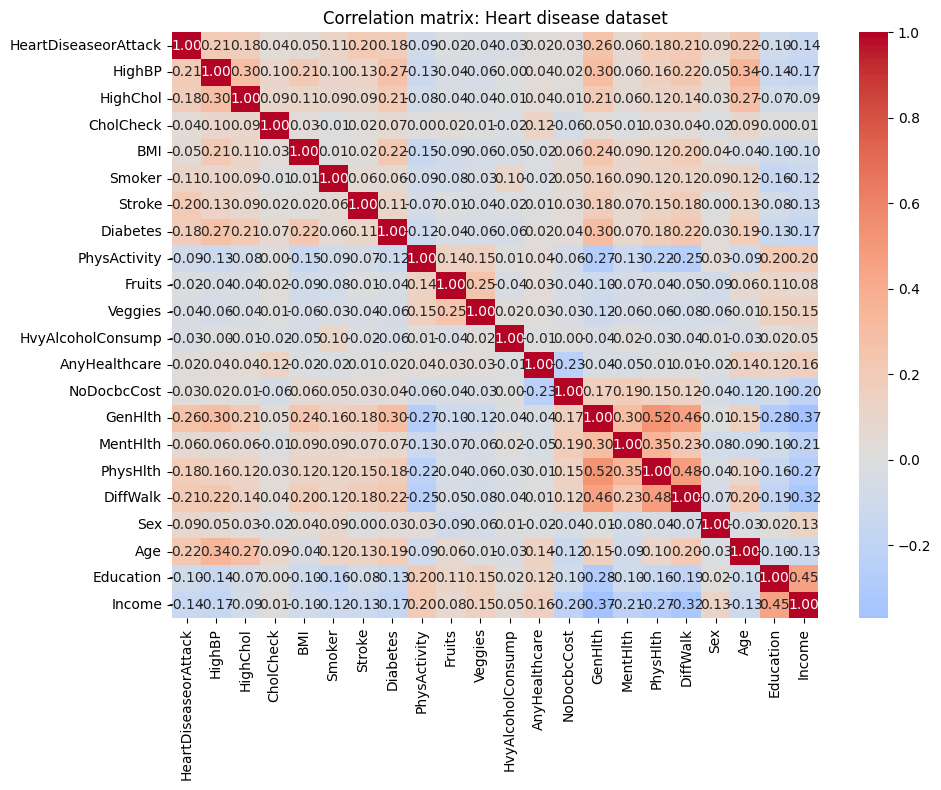

In [4]:
corr = df.select_dtypes(include="number").corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation matrix: Heart disease dataset")
plt.tight_layout()
plt.show()

### 5. Correlation with target, sorted

In [6]:
target = "HeartDiseaseorAttack"
corr[target].drop(target).sort_values(key=abs, ascending=False)

GenHlth              0.258383
Age                  0.221618
DiffWalk             0.212709
HighBP               0.209361
Stroke               0.203002
PhysHlth             0.181698
HighChol             0.180765
Diabetes             0.180272
Income              -0.141011
Smoker               0.114441
Education           -0.099600
PhysActivity        -0.087299
Sex                  0.086096
MentHlth             0.064621
BMI                  0.052904
CholCheck            0.044206
Veggies             -0.039167
NoDocbcCost          0.031000
HvyAlcoholConsump   -0.028991
Fruits              -0.019790
AnyHealthcare        0.018734
Name: HeartDiseaseorAttack, dtype: float64